# Preliminary analysis with Singular Value Decomposition on TRIGA-MC data

Quick exploratory notebook for a single LoFi/HiFi dataset split. 
**Rank-selection diagnostics** (energy criterion, Gavish–Donoho threshold, MAC, MC noise floor) 
are implemented in the main notebook `SingularValueDecomposition.ipynb` with full theory and figures.


Let us import the data

In [13]:
_stats = '_lowstats400'
# _stats = '_highstats'

import numpy as np
_tmp = np.load(f'../Data/flux_data{_stats}.npz', allow_pickle=True)

snaps = _tmp['flux']
params = _tmp['params']
centroids = _tmp['centroids']

del _tmp

Let us separate the data into a training and test set, the seed is set to 42 for reproducibility.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

train_indices, test_indices, train_params, test_params = train_test_split(np.arange(len(params)), params, test_size=0.1, random_state=42)

max_flux = snaps[:, train_indices].max()
train_data = snaps[:, train_indices] / max_flux
test_data  = snaps[:, test_indices] / max_flux

print(train_data.shape, test_data.shape)

(126750, 360) (126750, 40)


## Singular Value Decomposition (SVD)

Instead of working with the high-dimensional flux data (with dimension $\mathcal{N}_h$\sim 10^5$), we can use the Singular Value Decomposition (SVD) to reduce the dimensionality of the data and hence the state vector $\mathbf{u}$ is replaced by a low-dimensional representation $\mathbf{v} = \mathbb{U}\mathbf{u}$ being $\mathbb{U}$ the SVD modes.

Let us perform the SVD on the snaps matrix

In [15]:
from sklearn.decomposition import randomized_svd

modes, sing_vals, _ = randomized_svd(train_data, n_components=150, n_iter='auto')

Let us plot the singular values

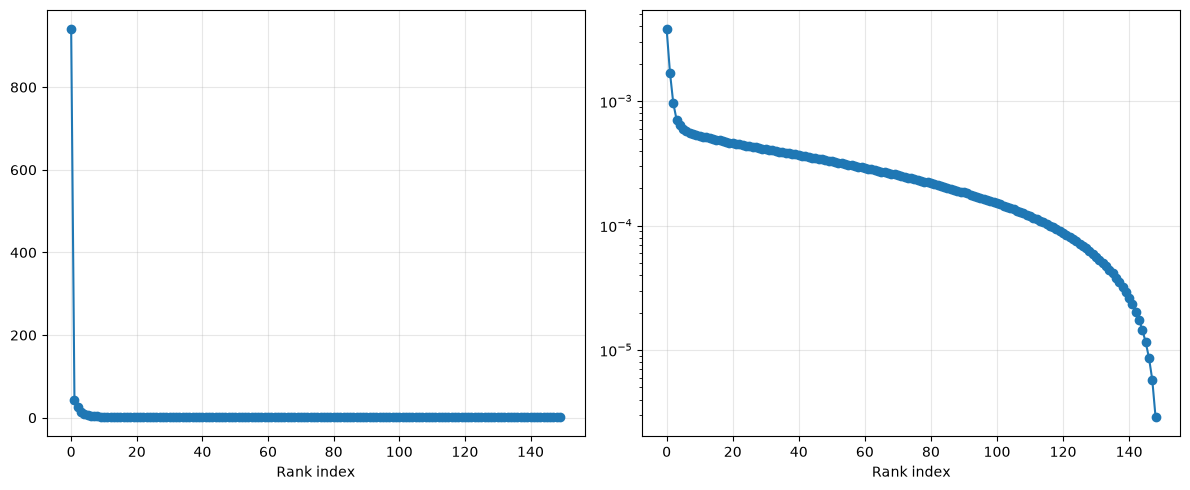

In [16]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

axs[0].plot(sing_vals, marker='o')
axs[1].semilogy(1 - np.cumsum(sing_vals[:-1]**2) / np.sum(sing_vals**2), marker='o')

for ax in axs:
    ax.set_xlabel('Rank index')
    ax.grid(True, alpha=0.3)
plt.tight_layout()


<>:14: SyntaxWarning: invalid escape sequence '\s'
<>:34: SyntaxWarning: invalid escape sequence '\s'
<>:43: SyntaxWarning: invalid escape sequence '\p'
<>:14: SyntaxWarning: invalid escape sequence '\s'
<>:34: SyntaxWarning: invalid escape sequence '\s'
<>:43: SyntaxWarning: invalid escape sequence '\p'
/var/folders/wj/ljx542lx73z3721_ddn_zwtc0000gp/T/ipykernel_79935/154051514.py:14: SyntaxWarning: invalid escape sequence '\s'
  ax.set_ylabel('Singular value $\sigma_r$')
/var/folders/wj/ljx542lx73z3721_ddn_zwtc0000gp/T/ipykernel_79935/154051514.py:34: SyntaxWarning: invalid escape sequence '\s'
  ax.set_ylabel('$\sigma_r^{LF} / \sigma_r^{HF}$')
/var/folders/wj/ljx542lx73z3721_ddn_zwtc0000gp/T/ipykernel_79935/154051514.py:43: SyntaxWarning: invalid escape sequence '\p'
  ax.set_ylabel('MAC($\phi_r^{LF},\phi_r^{HF}$)')


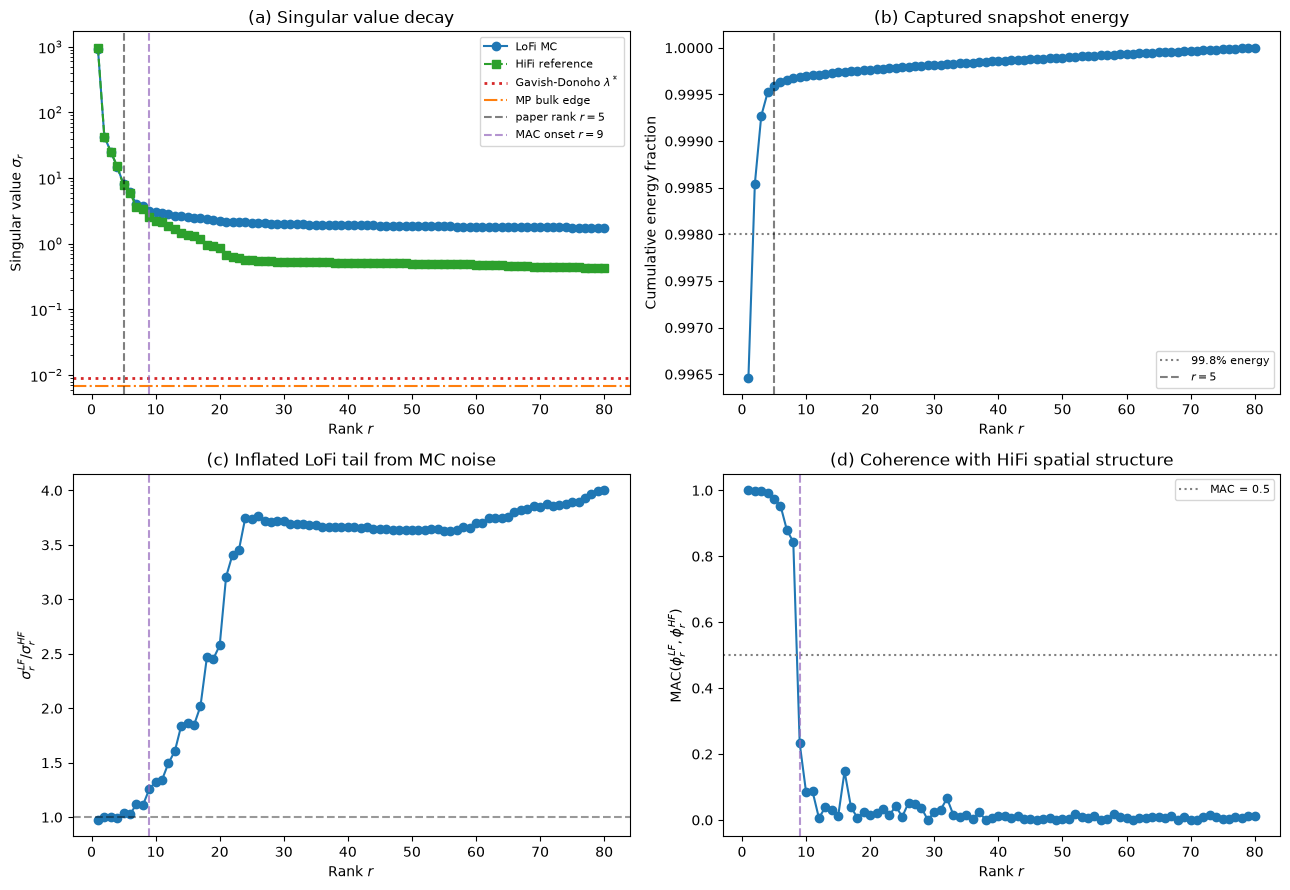

In [17]:
ranks = np.arange(1, n_sv + 1)

fig, axs = plt.subplots(2, 2, figsize=(13, 9))

# (a) singular value decay: LoFi vs HiFi
ax = axs[0, 0]
ax.semilogy(ranks, sing_vals[:n_sv], 'o-', label='LoFi MC', color='tab:blue')
ax.semilogy(ranks, sing_vals_hf[:n_sv], 's--', label='HiFi reference', color='tab:green')
ax.axhline(lambda_gd, color='tab:red', ls=':', lw=2, label=r'Gavish-Donoho $\lambda^*$')
ax.axhline(mp_bulk_edge, color='tab:orange', ls='-.', lw=1.5, label='MP bulk edge')
ax.axvline(rank_paper, color='k', ls='--', alpha=0.5, label='paper rank $r=5$')
ax.axvline(rank_mac_onset, color='tab:purple', ls='--', alpha=0.7, label=f'MAC onset $r={rank_mac_onset}$')
ax.set_xlabel('Rank $r$')
ax.set_ylabel('Singular value $\sigma_r$')
ax.set_title('(a) Singular value decay')
ax.legend(fontsize=8)

# (b) cumulative energy
ax = axs[0, 1]
ax.plot(ranks, energy[:n_sv], 'o-', color='tab:blue')
ax.axhline(0.998, color='gray', ls=':', label='99.8% energy')
ax.axvline(rank_paper, color='k', ls='--', alpha=0.5, label='$r=5$')
ax.set_xlabel('Rank $r$')
ax.set_ylabel('Cumulative energy fraction')
ax.set_title('(b) Captured snapshot energy')
ax.legend(fontsize=8)

# (c) LoFi/HiFi SV ratio — inflating tail indicates noise fitting
ax = axs[1, 0]
ax.plot(ranks, sv_ratio[:n_sv], 'o-', color='tab:blue')
ax.axhline(1.0, color='k', ls='--', alpha=0.4)
ax.axvline(rank_mac_onset, color='tab:purple', ls='--', alpha=0.7)
ax.set_xlabel('Rank $r$')
ax.set_ylabel('$\sigma_r^{LF} / \sigma_r^{HF}$')
ax.set_title('(c) Inflated LoFi tail from MC noise')

# (d) MAC between matched LoFi/HiFi modes
ax = axs[1, 1]
ax.plot(ranks, mac_diag[:n_sv], 'o-', color='tab:blue')
ax.axhline(0.5, color='gray', ls=':', label='MAC = 0.5')
ax.axvline(rank_mac_onset, color='tab:purple', ls='--', alpha=0.7)
ax.set_xlabel('Rank $r$')
ax.set_ylabel('MAC($\phi_r^{LF},\phi_r^{HF}$)')
ax.set_ylim(-0.05, 1.05)
ax.set_title('(d) Coherence with HiFi spatial structure')
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


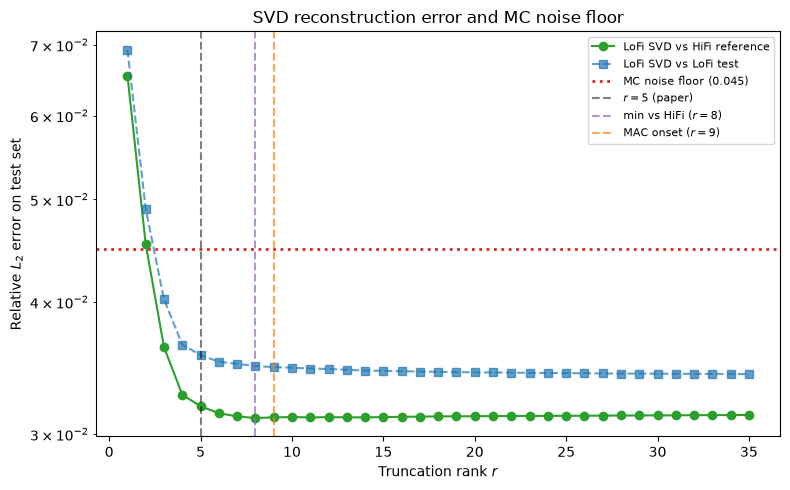

Best rank vs HiFi on test set: r=8 (error=0.0311)
Mean per-snapshot MC LoFi–HiFi relative L2: 0.0449


In [18]:
# Reconstruction error vs HiFi reference: noise floor from MC statistics
err_vs_hf = []
err_vs_lf = []
max_rank_err = 35
for rr in range(max_rank_err):
    rec = modes[:, : rr + 1] @ (modes[:, : rr + 1].T @ test_data)
    err_vs_hf.append(np.linalg.norm(rec - test_hf) / np.linalg.norm(test_hf))
    err_vs_lf.append(np.linalg.norm(rec - test_data) / np.linalg.norm(test_data))

mc_floor = np.mean(np.linalg.norm(test_data - test_hf, axis=0) / np.linalg.norm(test_hf, axis=0))
best_rank_hf = int(np.argmin(err_vs_hf) + 1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogy(range(1, max_rank_err + 1), err_vs_hf, 'o-', label='LoFi SVD vs HiFi reference', color='tab:green')
ax.semilogy(range(1, max_rank_err + 1), err_vs_lf, 's--', label='LoFi SVD vs LoFi test', color='tab:blue', alpha=0.7)
ax.axhline(mc_floor, color='tab:red', ls=':', lw=2, label=f'MC noise floor ({mc_floor:.3f})')
ax.axvline(rank_paper, color='k', ls='--', alpha=0.5, label='$r=5$ (paper)')
ax.axvline(best_rank_hf, color='tab:purple', ls='--', alpha=0.7, label=f'min vs HiFi ($r={best_rank_hf}$)')
ax.axvline(rank_mac_onset, color='tab:orange', ls='--', alpha=0.7, label=f'MAC onset ($r={rank_mac_onset}$)')
ax.set_xlabel('Truncation rank $r$')
ax.set_ylabel('Relative $L_2$ error on test set')
ax.set_title('SVD reconstruction error and MC noise floor')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f'Best rank vs HiFi on test set: r={best_rank_hf} (error={err_vs_hf[best_rank_hf-1]:.4f})')
print(f'Mean per-snapshot MC LoFi–HiFi relative L2: {mc_floor:.4f}')


**Discussion (LoFi `_lowstats400`).** The cumulative-energy criterion saturates very quickly ($r=5$ already captures $\gg 99.8\%$ of the LoFi snapshot energy), because the first few modes dominate the flux magnitude. However, **energy does not distinguish signal from MC noise**.

Comparing with the HiFi ensemble at the same CR parameters:
- Modes $1$–$8$ are highly coherent with HiFi ($\mathrm{MAC}\gtrsim 0.84$) and have comparable singular values ($\sigma_r^{LF}/\sigma_r^{HF}\approx 1$).
- From rank $\approx 9$ onward, MAC collapses ($\mathrm{MAC}<0.3$) and $\sigma_r^{LF}/\sigma_r^{HF}$ grows above $\sim 1.2$: the LoFi SVD begins to fit **MC-specific fluctuations** not present in the converged solution.
- Reconstruction error against HiFi improves up to $r\approx 8$ and then **plateaus near the MC noise floor**; adding more modes mainly reduces LoFi self-error while no longer improving agreement with HiFi.

The Gavish–Donoho threshold $\lambda^*=\omega(\beta)\,\hat\sigma_{MC}$ lies far below the leading singular values here (typical for low-rank signal + high-dimensional noise), so it does not contradict the energy-based choice $r=5$. It becomes informative when comparing **tail** singular values: the inflated LoFi tail relative to HiFi is the signature of MC variance on the decay curve.

This justifies using a **small rank** ($r=5$ in the main text) as an initial denoising step, while avoiding very large ranks that would re-introduce MC noise into the reduced state.


Let us plot the error as a function of the number of modes used

Text(0, 0.5, 'Relative error')

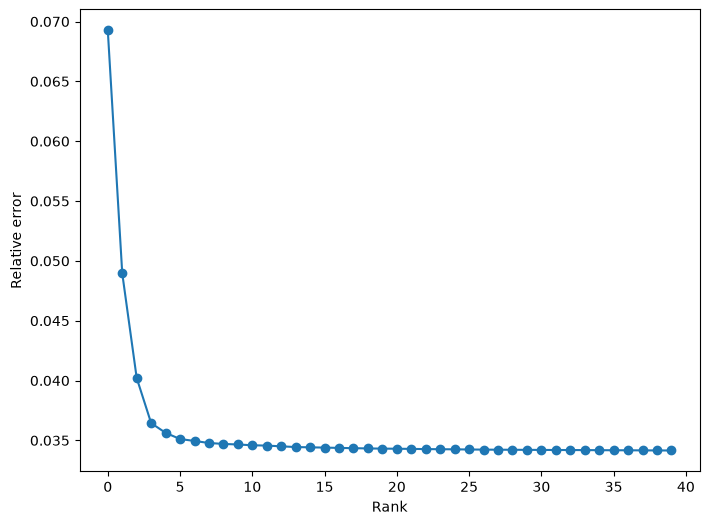

In [19]:
_err = list()
for rr in range(40):
    _test_pod = np.dot(modes[:,:rr+1].T, test_data)
    _test_rec = np.dot(modes[:,:rr+1], _test_pod)
    _err.append(np.linalg.norm(_test_rec - test_data) / np.linalg.norm(test_data))

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(_err, marker='o')
ax.set_xlabel('Rank')
ax.set_ylabel('Relative error')

Let us see the project the snapshots on the SVD modes and compute the error on the test set

In [ ]:
rank = 40
train_pod_coeffs = np.dot(modes[:,:rank].T, train_data)
test_pod_coeffs  = np.dot(modes[:,:rank].T, test_data)

Let us make some plots for test parameters

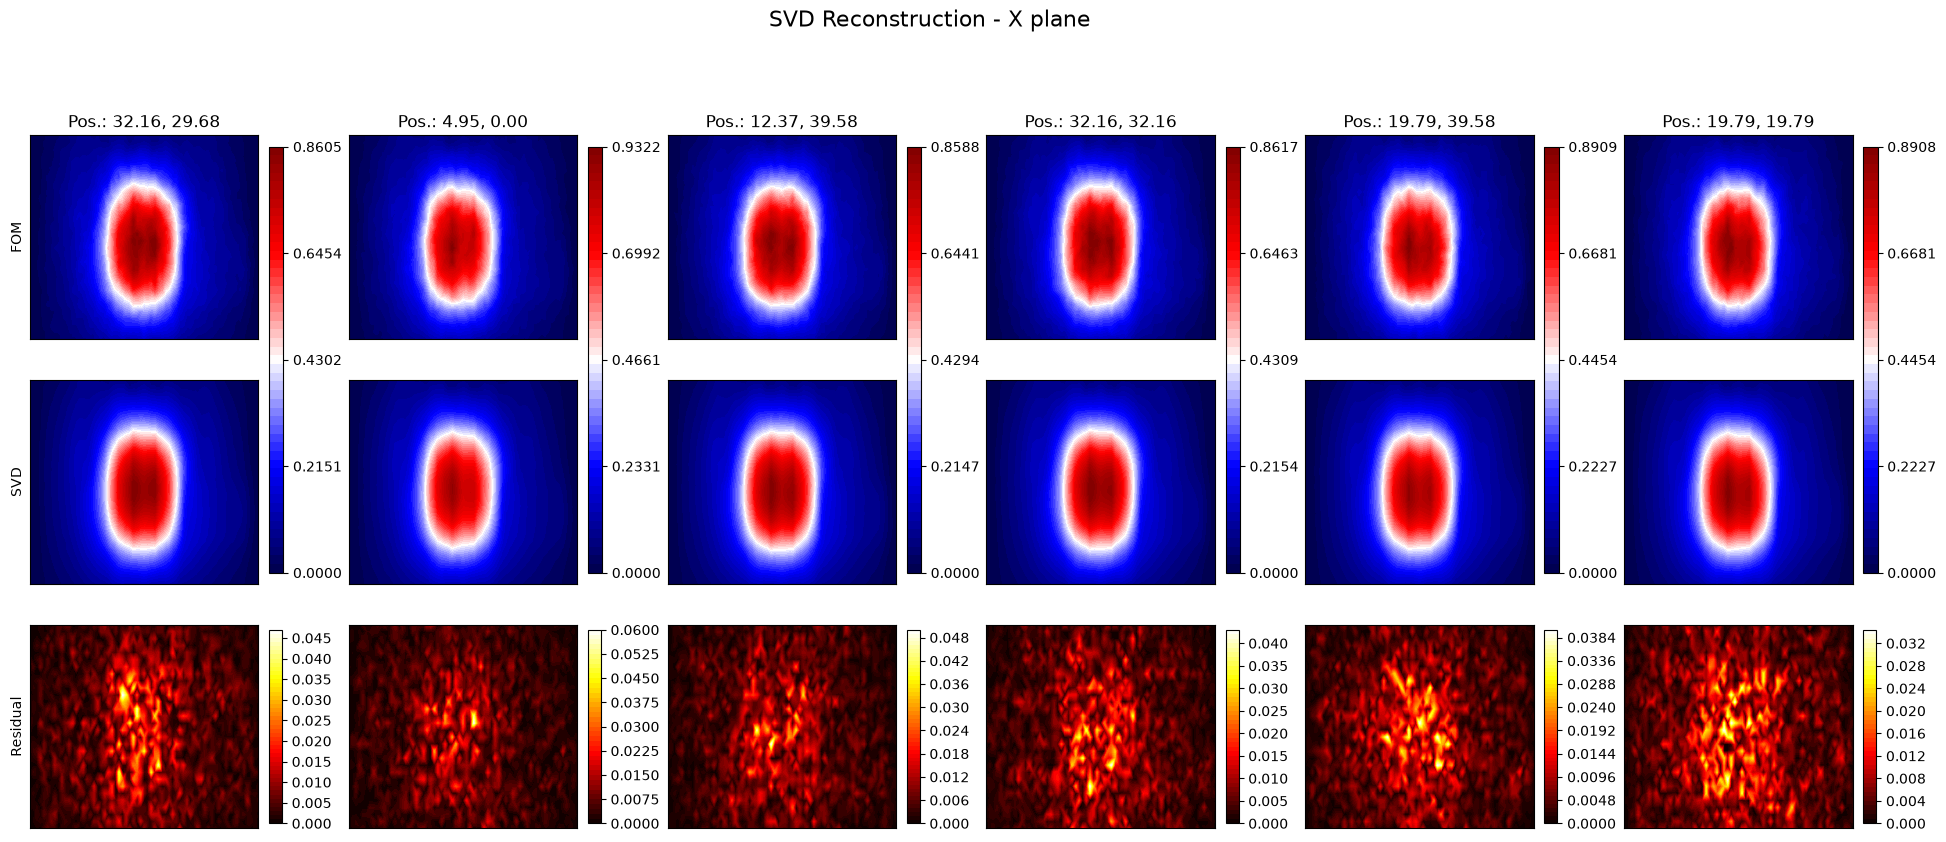

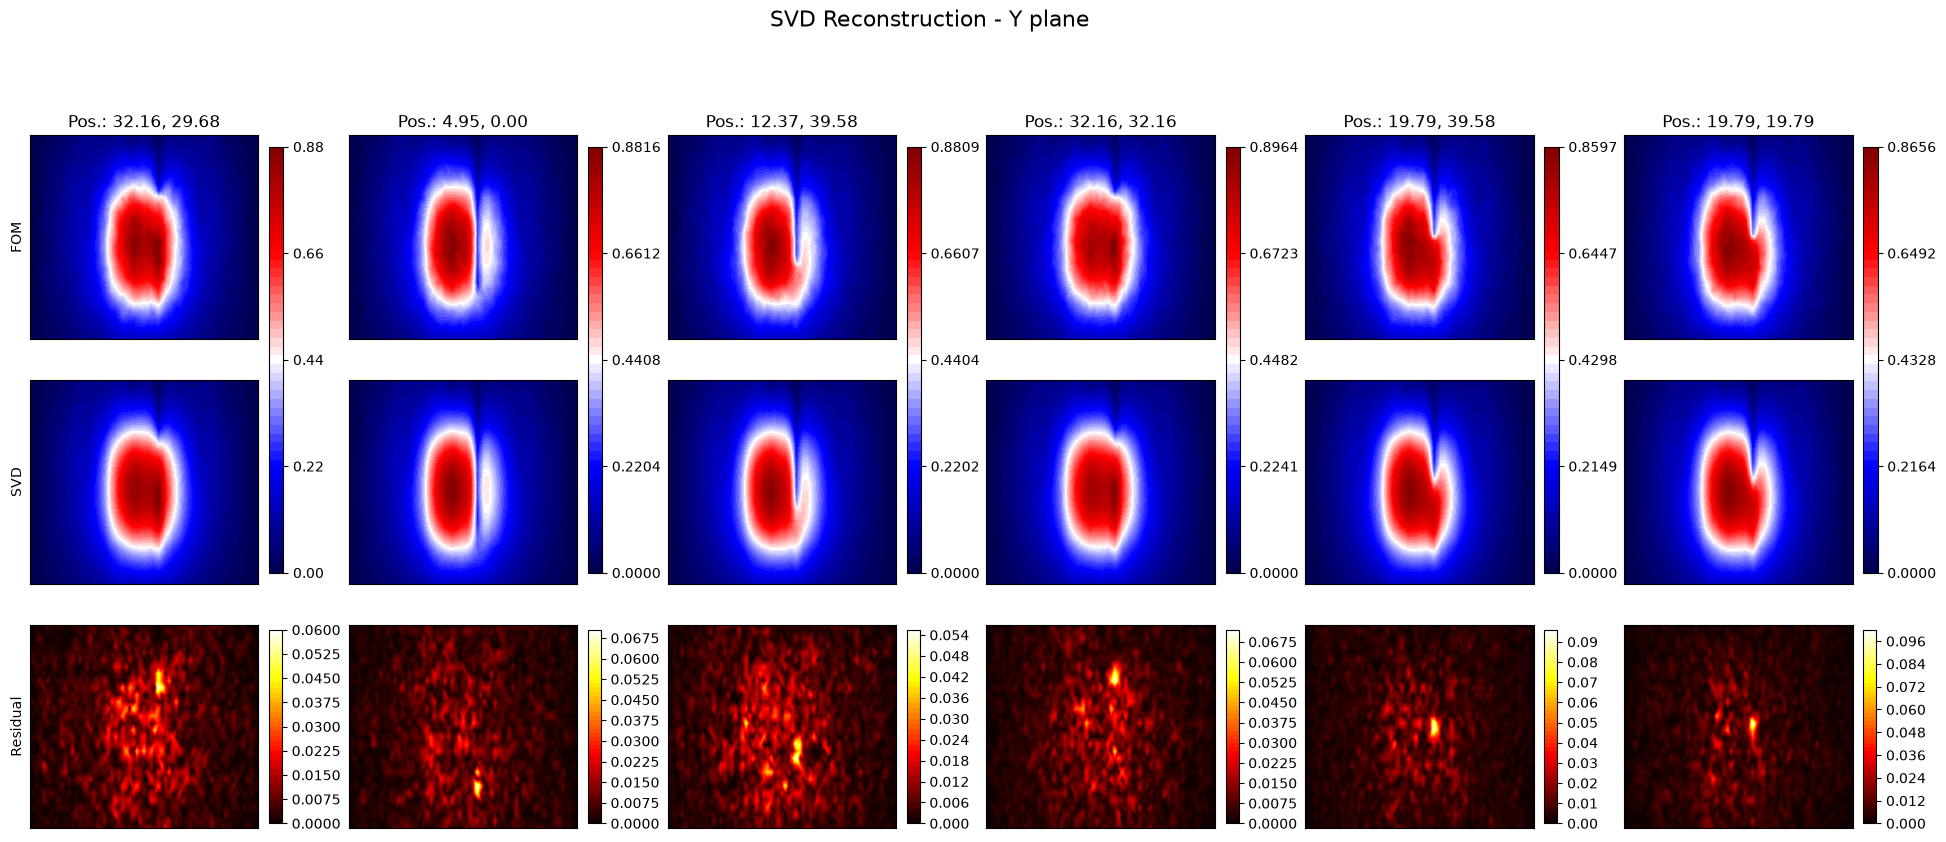

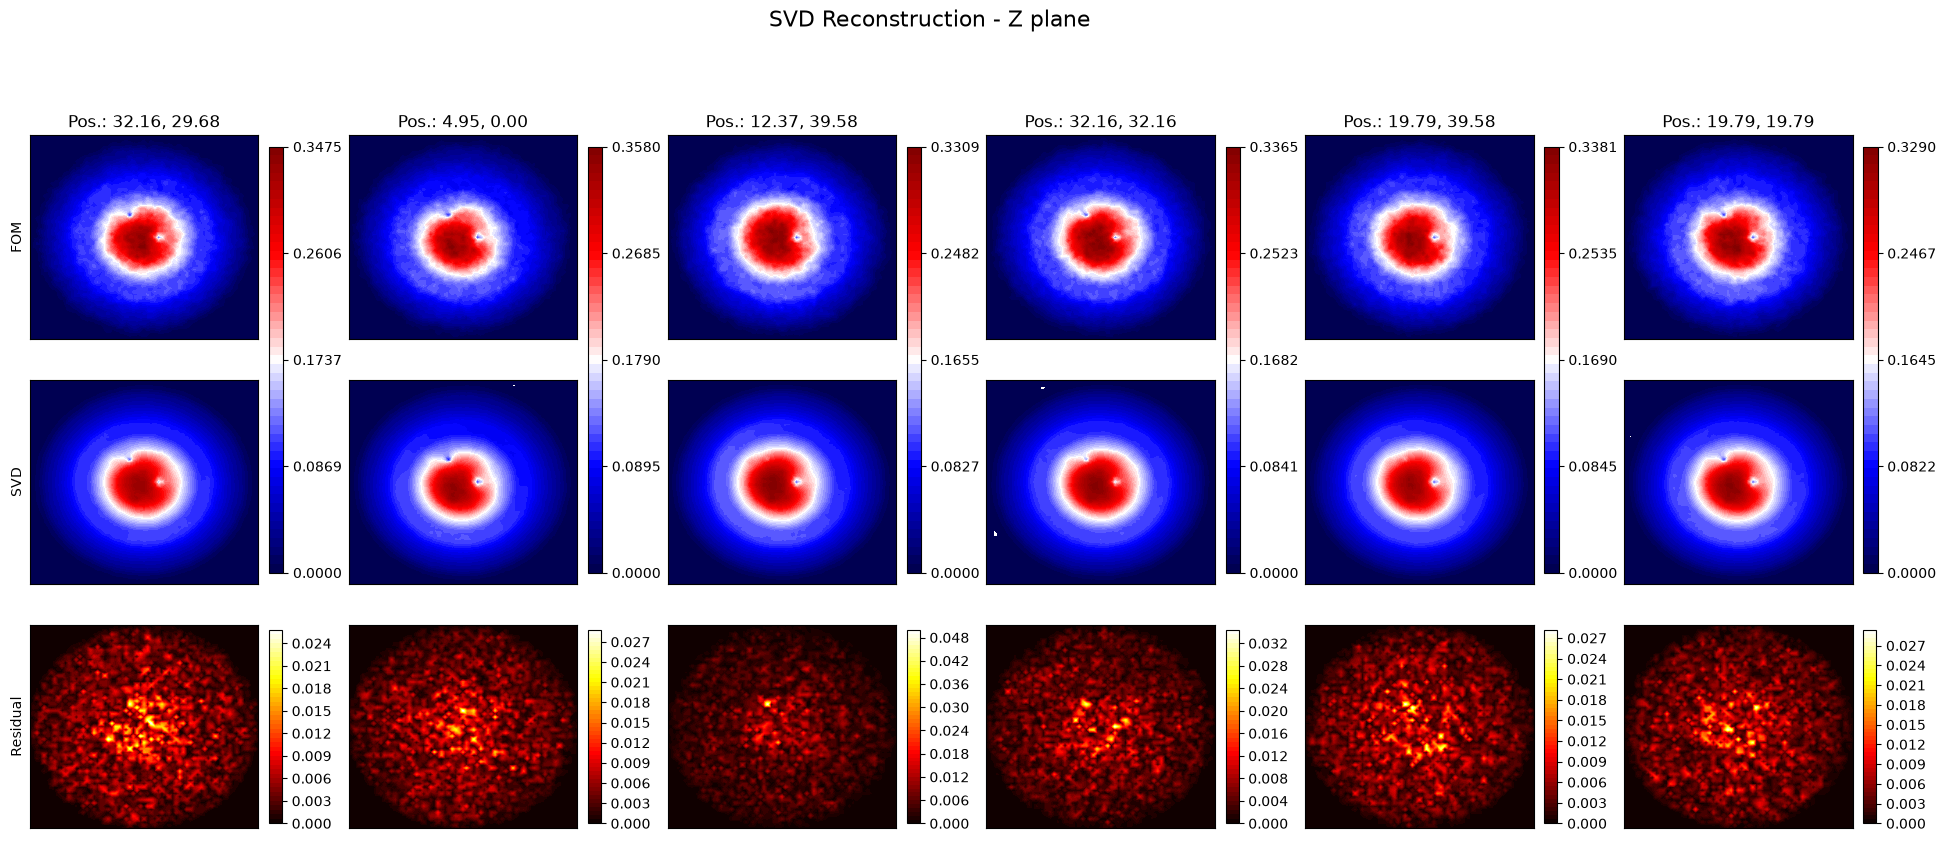

In [21]:
from utils.plots import PlotTriga
import pyvista as pv
from matplotlib import cm

pl = PlotTriga(pv.read(f'../Data/mesh{_stats}.vtk'))

cmap = cm.seismic

nrows = 3
ncols = 6

for normal in ['x', 'y', 'z']:


    fig, axs = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows))

    for ii in range(len(axs[0])):
        fom = test_data[:, ii]
        model_pred = np.dot(modes[:,:rank], test_pod_coeffs[:rank, ii])
        residual = np.abs(fom - model_pred)

        _slice_fom = pl.get_slice(fom, name='fom', plane_normal=normal)[1]

        levels = np.linspace(0, np.max(_slice_fom), 50)
        cont = pl.plot_slice(axs[0, ii], fom, normal=normal, levels=levels, cmap=cmap)
        pl.plot_slice(axs[1, ii], model_pred, normal=normal, levels=levels, cmap=cmap)
        res_cont = pl.plot_slice(axs[2, ii], residual, normal=normal, levels=len(levels), cmap='hot')

        cbar = fig.colorbar(cont, ax=axs[:2,ii], orientation='vertical', fraction=0.1, pad=0.04, shrink=0.95, aspect=30)
        cbar.ax.set_yticks(np.linspace(0, levels.max(), 5))

        cbar_res = fig.colorbar(res_cont, ax=axs[2,ii], orientation='vertical', fraction=0.1, pad=0.04, shrink=0.95, aspect=15)

        # Set titles 
        axs[0, ii].set_title('Pos.: {:.2f}, {:.2f}'.format(*test_params[ii]))

    for ax in axs.flatten():
        ax.set_xticks([])
        ax.set_yticks([])
        
    axs[0, 0].set_ylabel('FOM')
    axs[1, 0].set_ylabel('SVD')
    axs[2, 0].set_ylabel('Residual')
    fig.suptitle(f'SVD Reconstruction - {normal.upper()} plane', fontsize=16, y=1.02)

    plt.show()
    